In [12]:
# Basic stuff (paths, imports)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

environment = "WesternDesertTown"
# type = "Data_diff"
type = "Data_omni"
# trajectory = "P1000"
trajectory = "P0000"

trajectory_path = Path(environment) / type / trajectory
dataset_root = Path("data") / trajectory_path
imu_dir = dataset_root / "imu"

In [6]:
# Difference between global and local

vel_body = np.load(imu_dir / "vel_body.npy")
vel_global = np.load(imu_dir / "vel_global.npy")

print(
    f"vel_body[z-axis] == vel_global[z-axis]: {np.allclose(vel_body[:, 2], vel_global[:, 2])}"
)

acc_nograv_body = np.load(imu_dir / "acc_nograv_body.npy")
acc_nograv = np.load(imu_dir / "acc_nograv.npy")

print(
    f"acc_nograv_body[z-axis] == acc_nograv[z-axis]: {np.allclose(acc_nograv_body[:, 2], acc_nograv[:, 2])}"
)


vel_body[z-axis] == vel_global[z-axis]: True
acc_nograv_body[z-axis] == acc_nograv[z-axis]: True


In [23]:
def plot_xyz(imu_data: np.ndarray, title):

    plt.plot(imu_data[:, 0], label="X-axis")
    plt.plot(imu_data[:, 1], label="Y-axis")
    plt.plot(imu_data[:, 2], label="Z-axis")
    plt.title(title)
    plt.xlabel("Sample")
    plt.ylabel("Position Value")
    plt.legend()
    plt.show()


# plot_xyz(vel_body, "vel_body")
# plot_xyz(acc_nograv, "acc_nograv")

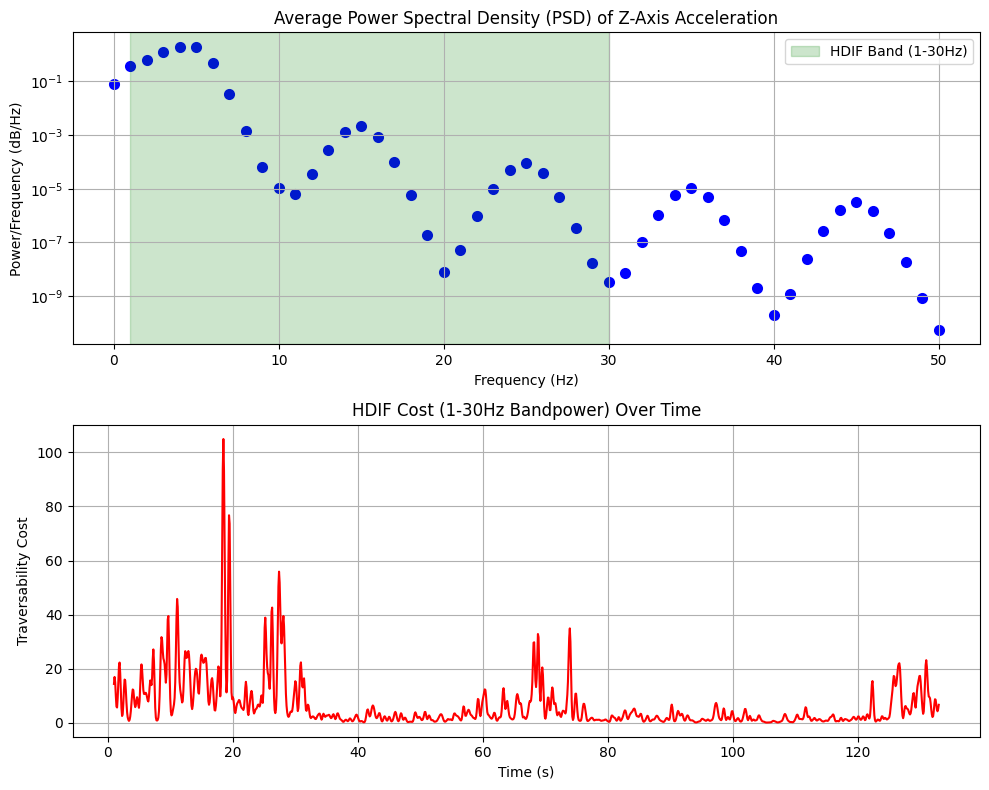

In [ ]:
import numpy as np
from scipy.integrate import simpson
from scipy.signal import welch

IMU_FPS = 100  # Hz
IMG_FPS = 10  # Hz
F_MIN = 1.0  # Lower frequency bound (Hz)
F_MAX = 30.0  # Upper frequency bound (Hz)
WINDOW_SEC = 1.0  # Sliding window duration (seconds)

# vel_body shape: [num_samples, 3] -> (vx, vy, vz)
vz = vel_body[:, 2]

# 2. Derive Acceleration
dt = 1.0 / IMU_FPS
# Calculate acceleration: a = dv/dt
# We pad with 0 at the start to maintain array length
az = np.diff(vz, prepend=vz[0]) / dt

# 3. Sliding Window Cost Calculation
window_samples = int(WINDOW_SEC * IMU_FPS)  # 1s * 100Hz = 100 samples
step_size = int(IMU_FPS / IMG_FPS)  # 100Hz / 10Hz = 10 samples (stride)

costs = []
timestamps = []
all_freqs = []
all_psds = []

# Iterate over the data with the sliding window
for i in range(window_samples, len(az), step_size):
    # Extract window (last 1 second of data)
    window_data = az[i - window_samples : i]

    # Compute Power Spectral Density (PSD) using Welch's method
    # nperseg determines frequency resolution.
    freqs, psd = welch(window_data, fs=IMU_FPS, nperseg=window_samples)

    # Store for the aggregate frequency plot
    all_freqs = freqs
    all_psds.append(psd)

    # Find indices corresponding to the 1-30 Hz band
    idx_band = np.logical_and(freqs >= F_MIN, freqs <= F_MAX)

    # Integrate PSD in the band to get Bandpower (The "Cost")
    # Using Simpson's rule for integration
    bandpower = simpson(psd[idx_band], dx=freqs[1] - freqs[0])

    costs.append(bandpower)
    timestamps.append(i / IMU_FPS)

costs = np.array(costs)
timestamps = np.array(timestamps)
avg_psd = np.mean(all_psds, axis=0)

# 4. Plotting
fig, axs = plt.subplots(2, 1, figsize=(10, 8))

# Plot 1: Frequency Analysis (Average PSD)
# This verifies if the dataset HAS energy in the 1-30Hz band.
axs[0].scatter(all_freqs, avg_psd, color="blue", linewidth=2)
axs[0].axvspan(F_MIN, F_MAX, color="green", alpha=0.2, label="HDIF Band (1-30Hz)")
axs[0].set_title("Average Power Spectral Density (PSD) of Z-Axis Acceleration")
axs[0].set_xlabel("Frequency (Hz)")
axs[0].set_ylabel("Power/Frequency (dB/Hz)")
axs[0].set_yscale("log")  # Log scale is better for PSD
axs[0].grid(True, which="both", ls="-")
axs[0].legend()

# Plot 2: Cost Function Over Time
# This shows the "Roughness" metric the network tries to learn.
axs[1].plot(timestamps, costs, color="red", linewidth=1.5)
axs[1].set_title("HDIF Cost (1-30Hz Bandpower) Over Time")
axs[1].set_xlabel("Time (s)")
axs[1].set_ylabel("Traversability Cost")
axs[1].grid(True)

plt.tight_layout()
plt.show()

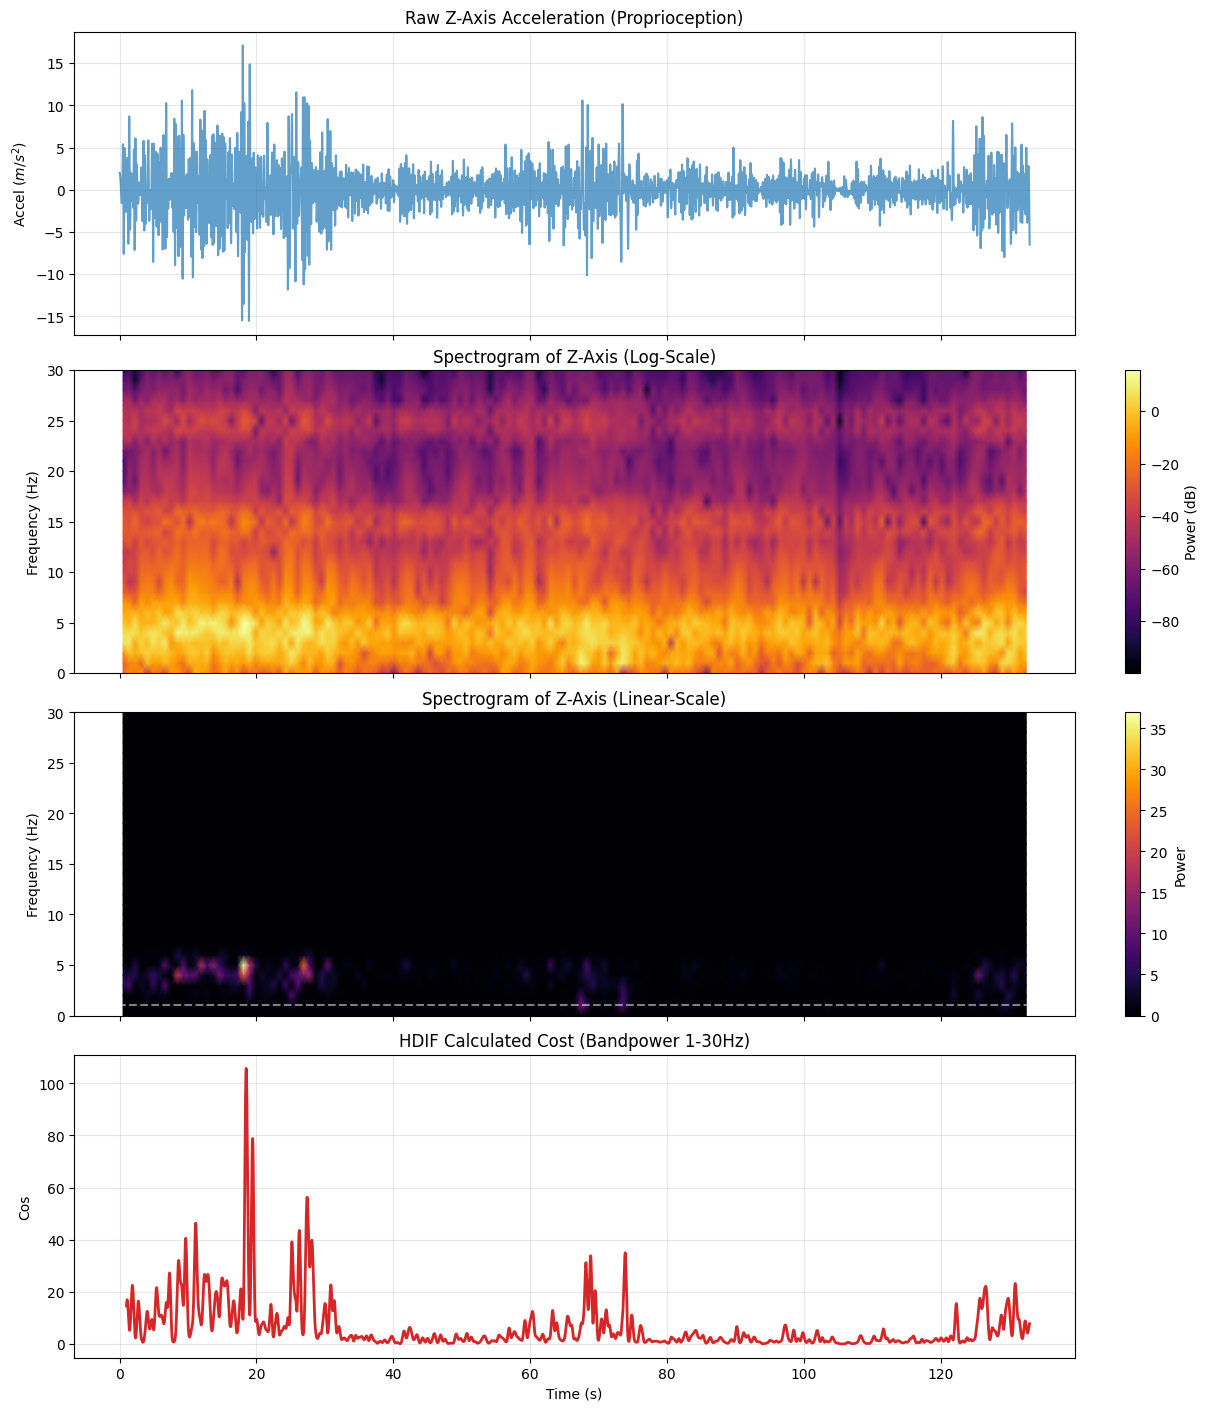

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Simpson's rule integration
from scipy.integrate import simpson
from scipy.signal import spectrogram, welch

# ==========================================
# 1. Setup and Data Loading
# ==========================================
# img_fps = 10
imu_fps = 100
window_sec = 1.0  # HDIF uses 1-second sliding window


num_samples = 1000
t = np.linspace(0, num_samples / imu_fps, num_samples)


# 2. HDIF Cost Function from the repo
def bandpower(data, sf, band, window_sec=None, relative=False):
    band = np.asarray(band)
    low, high = band
    if window_sec is not None:
        nperseg = int(window_sec * sf)
    else:
        nperseg = None

    freqs, psd = welch(data, sf, nperseg=nperseg)
    freq_res = freqs[1] - freqs[0]
    idx_band = np.logical_and(freqs >= low, freqs <= high)

    bp = simpson(psd[idx_band], dx=freq_res)

    if relative:
        bp /= simpson(psd, dx=freq_res)
    return bp


def calculate_rolling_cost(acc_z_data, sf):
    """
    Calculates the HDIF cost over the trajectory using a 1s sliding window.
    HDIF Paper: "sliding window of the last one second... frequency range 1-30 Hz" [cite: 82, 124]
    """
    costs = []
    timestamps = []

    window_samples = int(1.0 * sf)  # 1 second window

    # We step through the data.
    # Note: HDIF samples this at the location of image frames (10Hz)
    # but computes it using the previous 1s of IMU data.

    for i in range(window_samples, len(acc_z_data), 1):
        # Extract window
        window = acc_z_data[i - window_samples : i]

        # Calculate Cost (Bandpower 1-30Hz)
        # Note: sf//2 ensures we don't exceed Nyquist if sf is low,
        # but for 100Hz IMU, sf//2 = 50Hz, so [1, 30] is safe.
        upper_freq = min(30, sf // 2 - 1)
        cost = bandpower(window, sf, [1, upper_freq], window_sec=1.0)

        costs.append(cost)
        timestamps.append(i / sf)

    return np.array(timestamps), np.array(costs)


# ==========================================
# 3. Execution & Plotting
# ==========================================

# 3a. Extract Z-axis acceleration (Assuming index 2 is Z)
# Use acc_nograv_body as it represents pure motion forces without gravity bias
z_acc = acc_nograv_body[:, 2]

# 3b. Calculate Cost over time
ts_cost, costs = calculate_rolling_cost(z_acc, imu_fps)

# 3c. Plotting
fig, axs = plt.subplots(4, 1, figsize=(12, 14), constrained_layout=True, sharex=True)

# Plot 1: Raw Z-Acceleration
axs[0].plot(np.arange(len(z_acc)) / imu_fps, z_acc, alpha=0.7, color="tab:blue")
axs[0].set_title("Raw Z-Axis Acceleration (Proprioception)")
axs[0].set_ylabel("Accel ($m/s^2$)")
axs[0].grid(True, alpha=0.3)

# Plot 2: Spectrogram (Log-Scale)
f, t_spec, Sxx = spectrogram(z_acc, fs=imu_fps, nperseg=int(imu_fps))
pcm = axs[1].pcolormesh(
    t_spec,
    f,
    # 10 * np.log10((Sxx + 1e-10) / Sxx.max()),
    10 * np.log10((Sxx + 1e-10) / 1),
    shading="gouraud",
    cmap="inferno",
)
axs[1].set_title("Spectrogram of Z-Axis (Log-Scale)")
axs[1].set_ylabel("Frequency (Hz)")
axs[1].set_ylim(0, 30)  # Focus on HDIF interest band
plt.colorbar(pcm, ax=axs[1], label="Power (dB)")

# Plot 3: Spectrogram (Linear-Scale)
pcm2 = axs[2].pcolormesh(t_spec, f, Sxx, shading="gouraud", cmap="inferno")
axs[2].set_title("Spectrogram of Z-Axis (Linear-Scale)")
axs[2].set_ylabel("Frequency (Hz)")
axs[2].set_ylim(0, 30)  # Focus on HDIF interest band
axs[2].axhline(y=1, color="w", linestyle="--", alpha=0.5)
axs[2].axhline(y=30, color="w", linestyle="--", alpha=0.5)
plt.colorbar(pcm2, ax=axs[2], label="Power")

# Plot 4: HDIF Cost Function Over Time
axs[3].plot(ts_cost, costs, color="tab:red", linewidth=2)
axs[3].set_title("HDIF Calculated Cost (Bandpower 1-30Hz)")
axs[3].set_xlabel("Time (s)")
axs[3].set_ylabel("Cos")
axs[3].grid(True, alpha=0.3)


plt.show()

In [ ]:
from pathlib import Path

import imageio
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import simpson
from scipy.signal import welch

# ------------------------------
# Config
# ------------------------------
# environment = "ForestEnv"
# environment = "Rome"
# environment = "WaterMillDay"
# environment = "SeasonalForestWinter"
environment = "WesternDesertTown"
# type = "Data_diff"
type = "Data_omni"
# trajectory = "P1000"
trajectory = "P0000"

trajectory_path = Path(environment) / type / trajectory
dataset_root = Path("data") / trajectory_path
imu_dir = dataset_root / "imu"
camera_folders = ["image_lcam_bottom", "image_lcam_front"]
output_path = Path("output") / trajectory_path
output_path.mkdir(parents=True, exist_ok=True)
output_video = output_path / "imu_overlay_multi_cam.mp4"

img_fps = 10
imu_fps = 100
window_sec = 1.0
f_min, f_max = 1.0, 30.0

# ------------------------------
# Load IMU data
# ------------------------------
vel_path = imu_dir / "vel_body.npy"
imu_time_path = imu_dir / "imu_time.npy"
cam_time_path = imu_dir / "cam_time.npy"


acc_nograv_body = np.load(acc_path)
vel_body = np.load(vel_path)
imu_time = np.load(imu_time_path)
cam_time = np.load(cam_time_path)

# Use z-axis acceleration only
z_acc = acc_nograv_body[:, 2]

# Calculate speed (magnitude of velocity vector)
speed = np.linalg.norm(vel_body[:, 0:2], axis=1)


# ------------------------------
# HDIF cost calculation
# ------------------------------
def bandpower(data, sf, band, window_sec=None):
    band = np.asarray(band)
    low, high = band
    nperseg = int(window_sec * sf) if window_sec is not None else None
    freqs, psd = welch(data, sf, nperseg=nperseg)
    freq_res = freqs[1] - freqs[0]
    idx_band = np.logical_and(freqs >= low, freqs <= high)
    return simpson(psd[idx_band], dx=freq_res)


def rolling_cost(acc_z, timestamps, sf):
    window_samples = int(window_sec * sf)
    costs = np.full_like(acc_z, fill_value=np.nan, dtype=float)
    for i in range(window_samples, len(acc_z)):
        window = acc_z[i - window_samples : i]
        upper_freq = min(f_max, sf // 2 - 1)
        costs[i] = bandpower(window, sf, [f_min, upper_freq], window_sec=window_sec)
    return costs


costs = rolling_cost(z_acc, imu_time, imu_fps)

# Map each image timestamp to nearest imu index
imu_indices = np.searchsorted(imu_time, cam_time, side="left")
imu_indices = np.clip(imu_indices, 0, len(imu_time) - 1)

# ------------------------------
# Load camera images
# ------------------------------
camera_images = {}
for camera_folder in camera_folders:
    img_dir = dataset_root / camera_folder
    image_paths = sorted(
        [p for p in img_dir.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"}]
    )
    if not image_paths:
        raise FileNotFoundError(f"No images found in {img_dir}")
    camera_images[camera_folder] = image_paths

min_frame_count = min(len(cam_time), *(len(v) for v in camera_images.values()))
if min_frame_count == 0:
    raise ValueError("No frames available to render.")

# ------------------------------
# Build video with side plots
# ------------------------------
num_cams = len(camera_folders)
img_cols = 2 if num_cams > 1 else 1
img_rows = int(np.ceil(num_cams / img_cols))
fig_height = max(5, 3 * img_rows)
fig = plt.figure(figsize=(12, fig_height))
gs = fig.add_gridspec(3, 2, width_ratios=[2.5, 1.2], height_ratios=[1, 1, 1])
img_gs = gs[:, 0].subgridspec(img_rows, img_cols)

ax_imgs = []
for idx in range(img_rows * img_cols):
    ax = fig.add_subplot(img_gs[idx // img_cols, idx % img_cols])
    ax.axis("off")
    ax_imgs.append(ax)

ax_z = fig.add_subplot(gs[0, 1])
ax_cost = fig.add_subplot(gs[1, 1], sharex=ax_z)
ax_speed = fig.add_subplot(gs[2, 1], sharex=ax_z)

ax_z.plot(imu_time, z_acc, color="tab:blue", linewidth=0.8)
ax_z.set_title("Z-axis IMU (acc_nograv_body)")
ax_z.set_ylabel("Accel")
ax_z.set_xlim(imu_time[0], imu_time[-1])
ax_z.grid(True, alpha=0.3)
ax_z.tick_params(labelbottom=False)

ax_speed.plot(imu_time, speed, color="tab:green", linewidth=0.8)
ax_speed.set_title("Speed (vel_body)")
ax_speed.set_xlabel("Time (s)")
ax_speed.set_ylabel("Speed (m/s)")
ax_speed.set_xlim(imu_time[0], imu_time[-1])
ax_speed.grid(True, alpha=0.3)

ax_cost.plot(imu_time, costs, color="tab:red", linewidth=0.8)
ax_cost.set_title("HDIF Cost (1-30 Hz)")
ax_cost.set_ylabel("Cost")
ax_cost.set_xlim(imu_time[0], imu_time[-1])
ax_cost.grid(True, alpha=0.3)
ax_cost.tick_params(labelbottom=False)

# Moving markers
z_marker = ax_z.axvline(imu_time[0], color="black", linestyle="--", linewidth=1)
cost_marker = ax_cost.axvline(imu_time[0], color="black", linestyle="--", linewidth=1)
speed_marker = ax_speed.axvline(imu_time[0], color="black", linestyle="--", linewidth=1)

with imageio.get_writer(output_video, fps=img_fps) as writer:
    for frame_idx in range(min_frame_count):
        for cam_idx, camera_folder in enumerate(camera_folders):
            ax = ax_imgs[cam_idx]
            img_path = camera_images[camera_folder][frame_idx]
            img = imageio.imread(img_path)
            ax.imshow(img)
            ax.set_title(camera_folder)
            ax.axis("off")
        for ax in ax_imgs[num_cams:]:
            ax.cla()
            ax.axis("off")

        imu_idx = imu_indices[frame_idx]
        current_t = imu_time[imu_idx]
        z_marker.set_xdata([current_t, current_t])
        cost_marker.set_xdata([current_t, current_t])
        speed_marker.set_xdata([current_t, current_t])

        fig.canvas.draw()
        frame = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
        frame = frame.reshape(fig.canvas.get_width_height()[::-1] + (4,))
        frame = frame[:, :, :3]  # Convert RGBA to RGB
        writer.append_data(frame)

        for ax in ax_imgs[:num_cams]:
            ax.cla()
            ax.axis("off")

plt.close(fig)
print(f"Saved video to {output_video}")

/var/folders/_5/rqbc4q813m91wf1127hrqkzh0000gn/T/ipykernel_2488/1598126199.py:160: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(img_path)
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 500) to (1200, 512) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Saved video to output/WesternDesertTown/Data_omni/P0000/imu_overlay_multi_cam.mp4
